In [22]:
# import cython
import numpy as np
import matplotlib.pyplot as plt 
import glob

In [23]:
from OXmodeCython import OXmode_cython

In [24]:
# Check that MPS is available
import torch
from unet import UNet, TransformerNet
import torchvision.transforms as transforms

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

# if not torch.backends.mps.is_available():
#     if not torch.backends.mps.is_built():
#         print("MPS not available because the current PyTorch install was not "
#               "built with MPS enabled.")
#     else:
#         print("MPS not available because the current MacOS version is not 12.3+ "
#               "and/or you do not have an MPS-enabled device on this machine.")

# else:
#     device = torch.device("mps")

cuda:0


In [25]:
# savedmodel_list = glob.glob1('saved_model','TOPHAT_checkpoint_epoch_15*')
# savedmodel_list.sort()
# for f in savedmodel_list:
#     loss = torch.load('saved_model/'+f)['loss'].item()
#     print(f, ':', loss)

In [ ]:
# model = UNet(n_channels=3, n_classes=4, up_kernel_size=3)
target_size = [512,408]
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.4, dropout_p=0.4)
# model = TransformerNet(n_channels=1, n_classes=4,input_size=target_size, in_dropout_p = 0.25, dropout_p=0.3)
# model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_20_5_loss1.0486.pth')['model_state_dict'])
model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_25_36000_loss1.3957.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

/tmp/ipykernel_951371/349300451.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_27_36000_loss1.3792

UNet(
  (att): Transformer(
    (in_linear): Linear(in_features=512, out_features=1024, bias=True)
    (out_linear): Linear(in_features=1024, out_features=1024, bias=True)
    (blocks): Sequential(
      (0): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=1024, out_features=1024, bias=True)
        )
        (relu): ReLU(inplace=True)
        (ln): GroupNorm(1, 408, eps=1e-05, affine=True)
      )
      (1): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_proj):

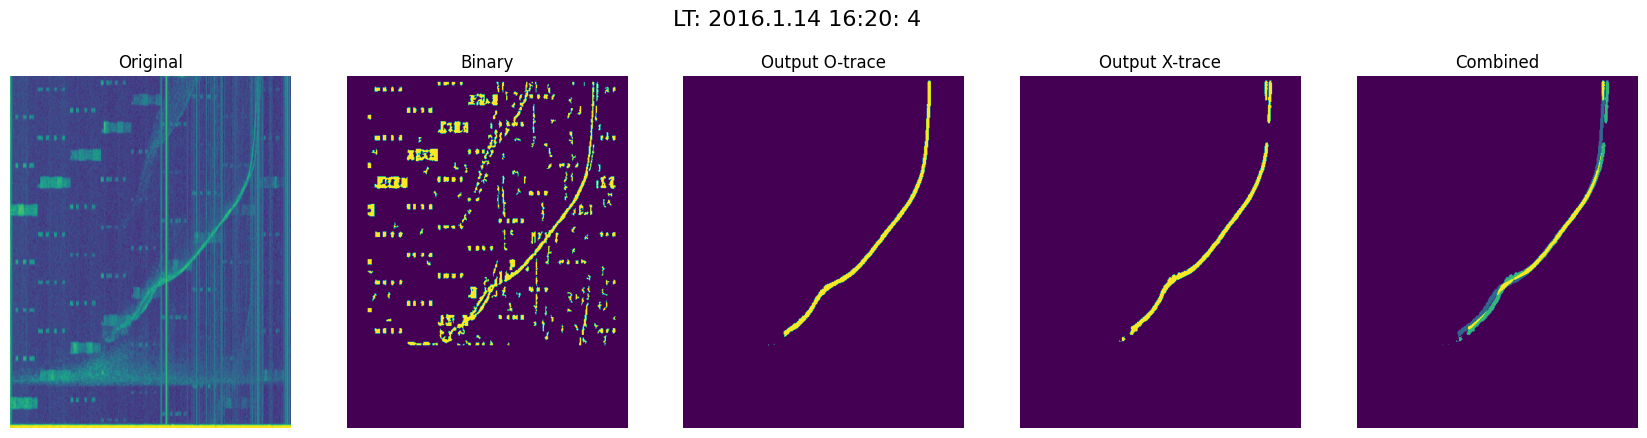

In [46]:
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    orgdata = np.load('VIPIR_PROC/org/' + file, allow_pickle=True, fix_imports=True)[()]
    # for i in orgdata:
    #     print(i)
    timestruct = orgdata['vipirTimeSct']
    localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"

    # print(timestruct)
    
    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(21, 5))
    # plt.title(f'epoch{epoch_num}_{file}')
    fig.suptitle(f'{localtime}', fontsize=16)

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[1]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[2]
    ax.imshow(imgO.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output O-trace')

    ax = axs[3]
    ax.imshow(imgX.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output X-trace')

    ax = axs[4]
    ax.imshow(imgO.numpy() + 2*imgX.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Combined')
# resize_back = transforms.Resize(ionogram.shape)


In [12]:


testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)
# resize_back = transforms.Resize(ionogram.shape)
# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    for file in testfiles:
        # file = testfiles[np.random.randint(0,len(testfiles)-1)]
        testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

        testimage1 = torch.from_numpy(testdata['mask_full']).float()

        orgdata = np.load('VIPIR_PROC/org/' + file, allow_pickle=True, fix_imports=True)[()]
        timestruct = orgdata['vipirTimeSct']
        localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"
        # testimage1 = resize_tr(testimage1[None,None,:,:])
        # img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
        img = testimage1[None,None,:,:]
        img = img.to('cuda')
        label1 = model(img)
        label1 = label1.squeeze().detach().cpu()

        imgO = torch.argmax(label1[0:2,:,:],dim=0)
        imgX = torch.argmax(label1[2:4,:,:],dim=0)
        imgO = imgO[None,:,:].squeeze().numpy() # resize_back(imgO[None,:,:]).squeeze().numpy()
        imgX = imgX[None,:,:].squeeze().numpy() # resize_back(imgX[None,:,:]).squeeze().numpy()
        testimage1 = testimage1.detach().squeeze().numpy()
        
        fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(21, 5))

        fig.suptitle(f'{localtime}',fontsize=16)

        # ax = axs[0]
        # ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
        # ax.axis('off')
        # ax.set_title('Ionogram in dB')

        # ax = axs[1]
        # ax.imshow(testimage1, origin='lower', aspect = 'auto')
        # ax.axis('off')
        # ax.set_title('Binary Ionogram')


        # ax = axs[2]
        # ax.imshow(imgO + imgX*2, origin='lower', aspect = 'auto')
        # ax.axis('off')
        # ax.set_title('Segmented O+X combined')

        ax = axs[0]
        ax.imshow(testimage1, origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Binarized Ionogram')
        
        ax = axs[1]
        ax.imshow(imgO, origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Output O-trace')

        ax = axs[2]
        ax.imshow(imgX, origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Output X-trace')

        ax = axs[3]
        ax.imshow(imgO + 2*imgX, origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Combined')

        ax = axs[4]
        ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('VIPIR Ionogram')

        plt.savefig(f'seg_result_transformer/{file[:-4]}.png', bbox_inches='tight')
        plt.close()

        np.save(f'seg_result_transformer/{file}', {'filename':file, 'image':testimage1, 'imgO': imgO, 'imgX': imgX})

In [ ]:
from scipy import ndimage
from skimage import morphology

import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    original = testdata['original']
    original -= (np.min(original)-1)
    original[np.isnan(original)] = 1

    temp1 = np.log10(original)

    sigma1 = 0.85
    sigma2 = 3

    gauss1 = ndimage.gaussian_filter(temp1,sigma1)
    gauss2 = ndimage.gaussian_filter(temp1,sigma2)
    out = gauss1-gauss2

    thresh = out > np.percentile(out,80,axis=0)
    
    temp3 = morphology.remove_small_objects(thresh, min_size=20, connectivity=1)
    # structure = np.ones([3,1])
    # temp = ndimage.binary_closing(temp3, structure)

    fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(21, 7))
    # plt.title(f'epoch{epoch_num}_{file}')

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal', cmap='gray')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[2]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[1]
    ax.imshow(out, origin='lower', aspect = 'equal', cmap='gray')
    ax.axis('off')
    ax.set_title('Difference of Gaussian')

    # ax = axs[3]
    # ax.imshow(imgX.numpy(), origin='lower', aspect = 'equal')
    # ax.axis('off')
    # ax.set_title('Output X-trace')

    ax = axs[3]
    imgO[imgX>0] = 2
    ax.imshow(imgO.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Segmentation')

# resize_back = transforms.Resize(ionogram.shape)